# 03 · Modelos de línea base (Etapa II)

**Fase CRISP-DM:** modelado. Se usan los modelos de línea base que
propone el informe:

- **Clase mayoritaria:** referencia mínima.
- **Regresión logística:** modelo lineal con log y estandarización.
- **Árbol de decisión:** modelo no lineal e interpretable.

Experimentos:

1. **Binario V1** (benigno vs. DDoS), entrenado solo con benigno + SYN y
   evaluado con todas las clases. Mide qué ocurre ante una variante de
   DDoS no vista (UDP).
2. **Binario V2**, entrenado con benigno + SYN + UDP (las clases de la
   Presentación 2). Con cinco clases mide además qué ocurre ante MQTT e
   ICMP, que no vio.
3. **Binario V3**, entrenado con todas las clases (solo con cinco clases).
4. **Multiclase:** todas las clases de `CLASES`.

Todos los modelos se evalúan en validación y en la prueba oficial
(dentro del dominio IoMT). Las métricas se guardan en
`deliverables/resultados/`.

> **Etapa III — cinco clases.** Desde la Etapa III, `src/data_loader.py` incluye además
> **DDoS MQTT** (MQTT Publish Flood, clase 3) y **DDoS ICMP** (ICMP flood, clase 4), con una
> muestra de hasta 200.000 flujos de cada uno. Las salidas guardadas en este notebook
> corresponden a la última ejecución; para reproducir los resultados de la Presentación 2
> (solo benigno, SYN y UDP), definir `NIDS_ATAQUES_NUEVOS=0` antes de abrir Jupyter.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ.resolve()))

from src.evaluate import configurar_graficos
configurar_graficos()

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier

from src.data_loader import CLASES, CARPETA_MODELOS, cargar_procesado, cargar_variables
from src.features import preprocesador
from src.evaluate import evaluar, matriz_confusion, guardar_tabla

config = cargar_variables()
variables = config["variables"]
SEMILLA = config["semilla"]

train = cargar_procesado("train")
val = cargar_procesado("val")
test = cargar_procesado("test")

print("Variables:", len(variables))
print("Entrenamiento:", train.shape, "| Validación:", val.shape, "| Prueba oficial:", test.shape)

Variables: 35
Entrenamiento: (660724, 37) | Validación: (165181, 37) | Prueba oficial: (624074, 37)


In [2]:
def modelos_base():
    """Modelos nuevos sin entrenar; se crean de nuevo en cada experimento."""
    return {
        "Clase mayoritaria": make_pipeline(
            preprocesador(),
            DummyClassifier(strategy="most_frequent"),
        ),
        "Regresión logística": make_pipeline(
            preprocesador(escalar=True),
            LogisticRegression(max_iter=1000, class_weight="balanced"),
        ),
        "Árbol de decisión": make_pipeline(
            preprocesador(),
            DecisionTreeClassifier(
                max_depth=5,
                min_samples_leaf=50,
                class_weight="balanced",
                random_state=SEMILLA,
            ),
        ),
    }

## 1. Clasificación binaria: V1, V2 y V3

In [3]:
escenarios = {
    "V1: benigno + SYN": [0, 1],
    "V2: benigno + SYN + UDP": [0, 1, 2],
}
if len(CLASES) > 3:
    escenarios["V3: todas las clases"] = list(CLASES)
ESCENARIO_COMPLETO = list(escenarios)[-1]  # el que usa todas las clases disponibles

filas_val, filas_test = [], []
binarios = {}

for escenario, clases in escenarios.items():
    subconjunto = train[train["clase"].isin(clases)]

    for nombre, modelo in modelos_base().items():
        modelo.fit(subconjunto[variables], subconjunto["etiqueta"])
        binarios[(escenario, nombre)] = modelo

        for filas, datos in [(filas_val, val), (filas_test, test)]:
            filas.append({
                "Escenario": escenario,
                "Modelo": nombre,
                **evaluar(modelo, datos[variables], datos["etiqueta"],
                          "binaria", clase_real=datos["clase"]),
            })

binaria_val = pd.DataFrame(filas_val).set_index(["Escenario", "Modelo"])
binaria_test = pd.DataFrame(filas_test).set_index(["Escenario", "Modelo"])

print("Validación")
display(binaria_val.round(4))
print("Prueba oficial")
display(binaria_test.round(4))

guardar_tabla(binaria_val, "metricas_validacion")
guardar_tabla(binaria_test, "metricas_prueba_oficial")

Validación


Accuracy  Precision DDoS  \
Escenario               Modelo                                          
V1: benigno + SYN       Clase mayoritaria      0.7666          0.7666   
                        Regresión logística    0.4997          0.9999   
                        Árbol de decisión      0.4758          0.9999   
V2: benigno + SYN + UDP Clase mayoritaria      0.7666          0.7666   
                        Regresión logística    0.9002          0.9999   
                        Árbol de decisión      0.7296          1.0000   
V3: todas las clases    Clase mayoritaria      0.7666          0.7666   
                        Regresión logística    0.9992          0.9998   
                        Árbol de decisión      0.9983          1.0000   

                                             Recall DDoS  F1 DDoS  F1 macro  \
Escenario               Modelo                                                
V1: benigno + SYN       Clase mayoritaria         1.0000   0.8679    0.4340   
                        Regresión logística       0.3475   0.5157    0.4992   
                        Árbol de decisión         0.3162   0.4805    0.4757   
V2: benigno + SYN + UDP Clase mayoritaria         1.0000   0.8679    0.4340   
                        Regresión logística       0.8699   0.9304    0.8771   
                        Árbol de decisión         0.6473   0.7858    0.7095   
V3: todas las clases    Clase mayoritaria         1.0000   0.8679    0.4340   
                        Regresión logística       0.9991   0.9995    0.9988   
                        Árbol de decisión         0.9978   0.9989    0.9976   

                                             Tasa falsos positivos  PR-AUC  \
Escenario               Modelo                                               
V1: benigno + SYN       Clase mayoritaria                   1.0000  0.7666   
                        Regresión logística                 0.0002  0.8179   
                        Árbol de decisión                   0.0001  0.9192   
V2: benigno + SYN + UDP Clase mayoritaria                   1.0000  0.7666   
                        Regresión logística                 0.0003  0.9996   
                        Árbol de decisión                   0.0001  0.9152   
V3: todas las clases    Clase mayoritaria                   1.0000  0.7666   
                        Regresión logística                 0.0008  1.0000   
                        Árbol de decisión                   0.0001  0.9998   

                                             Recall SYN  Recall UDP  \
Escenario               Modelo                                        
V1: benigno + SYN       Clase mayoritaria        1.0000      1.0000   
                        Regresión logística      0.9996      0.0000   
                        Árbol de decisión        0.9993      0.0000   
V2: benigno + SYN + UDP Clase mayoritaria        1.0000      1.0000   
                        Regresión logística      0.9994      0.9999   
                        Árbol de decisión        0.9989      0.9996   
V3: todas las clases    Clase mayoritaria        1.0000      1.0000   
                        Regresión logística      0.9994      0.9996   
                        Árbol de decisión        0.9988      0.9965   

                                             Recall MQTT  Recall ICMP  \
Escenario               Modelo                                          
V1: benigno + SYN       Clase mayoritaria         1.0000       1.0000   
                        Regresión logística       0.7488       0.0001   
                        Árbol de decisión         0.0357       0.0000   
V2: benigno + SYN + UDP Clase mayoritaria         1.0000       1.0000   
                        Regresión logística       0.2818       0.6880   
                        Árbol de decisión         0.1643       0.0001   
V3: todas las clases    Clase mayoritaria         1.0000       1.0000   
                        Regresión logística       0.9908       0.9996   


Prueba oficial


Accuracy  Precision DDoS  \
Escenario               Modelo                                          
V1: benigno + SYN       Clase mayoritaria      0.9397          0.9397   
                        Regresión logística    0.3377          1.0000   
                        Árbol de decisión      0.3357          1.0000   
V2: benigno + SYN + UDP Clase mayoritaria      0.9397          0.9397   
                        Regresión logística    0.8421          1.0000   
                        Árbol de decisión      0.6651          1.0000   
V3: todas las clases    Clase mayoritaria      0.9397          0.9397   
                        Regresión logística    0.9876          1.0000   
                        Árbol de decisión      0.9857          1.0000   

                                             Recall DDoS  F1 DDoS  F1 macro  \
Escenario               Modelo                                                
V1: benigno + SYN       Clase mayoritaria         1.0000   0.9689    0.4845   
                        Regresión logística       0.2952   0.4559    0.3049   
                        Árbol de decisión         0.2931   0.4533    0.3034   
V2: benigno + SYN + UDP Clase mayoritaria         1.0000   0.9689    0.4845   
                        Regresión logística       0.8320   0.9083    0.6705   
                        Árbol de decisión         0.6437   0.7832    0.5239   
V3: todas las clases    Clase mayoritaria         1.0000   0.9689    0.4845   
                        Regresión logística       0.9868   0.9933    0.9499   
                        Árbol de decisión         0.9848   0.9923    0.9432   

                                             Tasa falsos positivos  PR-AUC  \
Escenario               Modelo                                               
V1: benigno + SYN       Clase mayoritaria                   1.0000  0.9397   
                        Regresión logística                 0.0002  0.9495   
                        Árbol de decisión                   0.0001  0.9777   
V2: benigno + SYN + UDP Clase mayoritaria                   1.0000  0.9397   
                        Regresión logística                 0.0003  0.9999   
                        Árbol de decisión                   0.0002  0.9781   
V3: todas las clases    Clase mayoritaria                   1.0000  0.9397   
                        Regresión logística                 0.0005  1.0000   
                        Árbol de decisión                   0.0000  0.9992   

                                             Recall SYN  Recall UDP  \
Escenario               Modelo                                        
V1: benigno + SYN       Clase mayoritaria        1.0000      1.0000   
                        Regresión logística      0.9971      0.0000   
                        Árbol de decisión        0.9968      0.0000   
V2: benigno + SYN + UDP Clase mayoritaria        1.0000      1.0000   
                        Regresión logística      0.9971      0.9995   
                        Árbol de decisión        0.9969      0.9994   
V3: todas las clases    Clase mayoritaria        1.0000      1.0000   
                        Regresión logística      0.9971      0.9994   
                        Árbol de decisión        0.9968      0.9967   

                                             Recall MQTT  Recall ICMP  \
Escenario               Modelo                                          
V1: benigno + SYN       Clase mayoritaria         1.0000       1.0000   
                        Regresión logística       0.1481       0.0000   
                        Árbol de decisión         0.0036       0.0000   
V2: benigno + SYN + UDP Clase mayoritaria         1.0000       1.0000   
                        Regresión logística       0.0324       0.5511   
                        Árbol de decisión         0.0107       0.0001   
V3: todas las clases    Clase mayoritaria         1.0000       1.0000   
                        Regresión logística       0.1615       0.9997   


PosixPath('/Users/makise/Documents/GitHub/Data-Science/Sin título/deliverables/resultados/metricas_prueba_oficial.csv')

**Cómo leer la tabla:** en V1, el recall de UDP muestra si el modelo
reconoce una variante de DDoS que no vio en entrenamiento. Un recall
cercano a 0 indica la "ceguera ante vectores DDoS" descrita en el
informe. En V2, esa variante sí forma parte del entrenamiento; con
cinco clases, los recall de MQTT e ICMP de V2 muestran la misma prueba con
ataques nuevos. En V3 todas las variantes forman parte del entrenamiento.

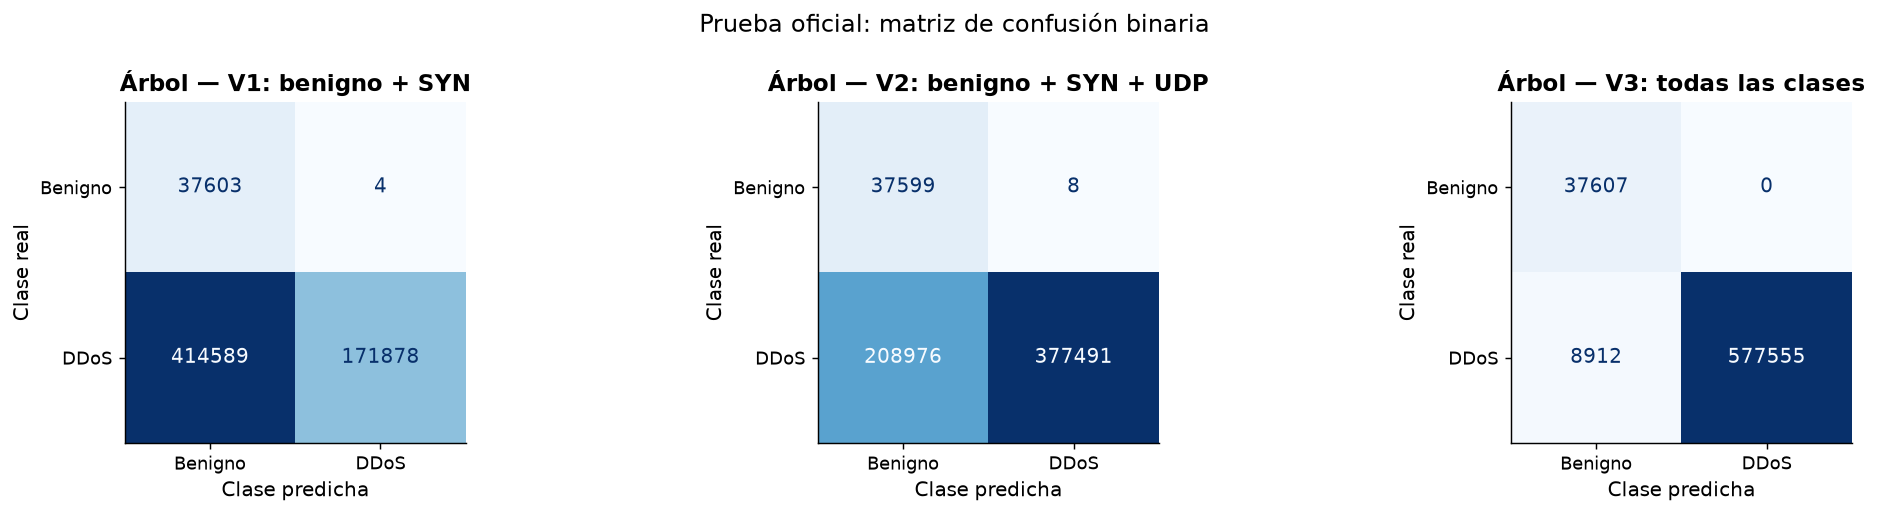


V1: benigno + SYN — proporción por clase real (prueba oficial)


Predicción,Predicho DDoS,Predicho benigno
Clase real,,
Benigno,0.0001,0.9999
DDoS ICMP,0.0000,1.0000
DDoS MQTT,0.0036,0.9964
DDoS SYN,0.9968,0.0032
DDoS UDP,0.0000,1.0000



V2: benigno + SYN + UDP — proporción por clase real (prueba oficial)


Predicción,Predicho DDoS,Predicho benigno
Clase real,,
Benigno,0.0002,0.9998
DDoS ICMP,0.0001,0.9999
DDoS MQTT,0.0107,0.9893
DDoS SYN,0.9969,0.0031
DDoS UDP,0.9994,0.0006



V3: todas las clases — proporción por clase real (prueba oficial)


Predicción,Predicho DDoS,Predicho benigno
Clase real,,
Benigno,0.0000,1.0000
DDoS ICMP,0.9996,0.0004
DDoS MQTT,0.0985,0.9015
DDoS SYN,0.9968,0.0032
DDoS UDP,0.9967,0.0033


In [4]:
fig, axes = plt.subplots(1, len(escenarios), figsize=(5.5 * len(escenarios), 4))
for ax, escenario in zip(axes, escenarios):
    modelo = binarios[(escenario, "Árbol de decisión")]
    matriz_confusion(
        test["etiqueta"], modelo.predict(test[variables]),
        "binaria", f"Árbol — {escenario}", ax=ax,
    )
fig.suptitle("Prueba oficial: matriz de confusión binaria")
plt.tight_layout()
plt.show()

# Detección según la variante real de cada registro
for escenario in escenarios:
    modelo = binarios[(escenario, "Árbol de decisión")]
    tabla = pd.crosstab(
        test["clase"].map(CLASES),
        np.where(modelo.predict(test[variables]) == 1, "Predicho DDoS", "Predicho benigno"),
        rownames=["Clase real"],
        colnames=["Predicción"],
        normalize="index",
    )
    print(f"\n{escenario} — proporción por clase real (prueba oficial)")
    display(tabla.round(4))

## 2. Clasificación multiclase

In [5]:
filas_val, filas_test = [], []
multiclase = {}

for nombre, modelo in modelos_base().items():
    modelo.fit(train[variables], train["clase"])
    multiclase[nombre] = modelo

    filas_val.append({"Modelo": nombre, **evaluar(
        modelo, val[variables], val["clase"], "multiclase")})
    filas_test.append({"Modelo": nombre, **evaluar(
        modelo, test[variables], test["clase"], "multiclase")})

multi_val = pd.DataFrame(filas_val).set_index("Modelo")
multi_test = pd.DataFrame(filas_test).set_index("Modelo")

print("Validación")
display(multi_val.round(4))
print("Prueba oficial")
display(multi_test.round(4))

guardar_tabla(multi_val, "metricas_multiclase_base_validacion")
guardar_tabla(multi_test, "metricas_multiclase_base_prueba_oficial")

Validación


,Accuracy,Precision macro,Recall macro,F1 macro,Recall Benigno,Recall DDoS SYN,Recall DDoS UDP,Recall DDoS MQTT,Recall DDoS ICMP,Tasa falsos positivos
Modelo,,,,,,,,,,
Clase mayoritaria,0.2496,0.0499,0.2000,0.0799,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000
Regresión logística,0.9996,0.9993,0.9994,0.9994,0.9994,0.9996,0.9998,0.9987,0.9996,0.0006
Árbol de decisión,0.9964,0.9872,0.9965,0.9917,0.9909,0.9981,0.9965,0.9973,0.9996,0.0091


Prueba oficial


,Accuracy,Precision macro,Recall macro,F1 macro,Recall Benigno,Recall DDoS SYN,Recall DDoS UDP,Recall DDoS MQTT,Recall DDoS ICMP,Tasa falsos positivos
Modelo,,,,,,,,,,
Clase mayoritaria,0.3295,0.0659,0.2000,0.0991,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000
Regresión logística,0.9927,0.9769,0.9075,0.9284,0.9996,0.9971,0.9995,0.5417,0.9997,0.0004
Árbol de decisión,0.9847,0.8673,0.8175,0.8124,0.9924,0.9944,0.9967,0.1043,0.9996,0.0076


PosixPath('/Users/makise/Documents/GitHub/Data-Science/Sin título/deliverables/resultados/metricas_multiclase_base_prueba_oficial.csv')

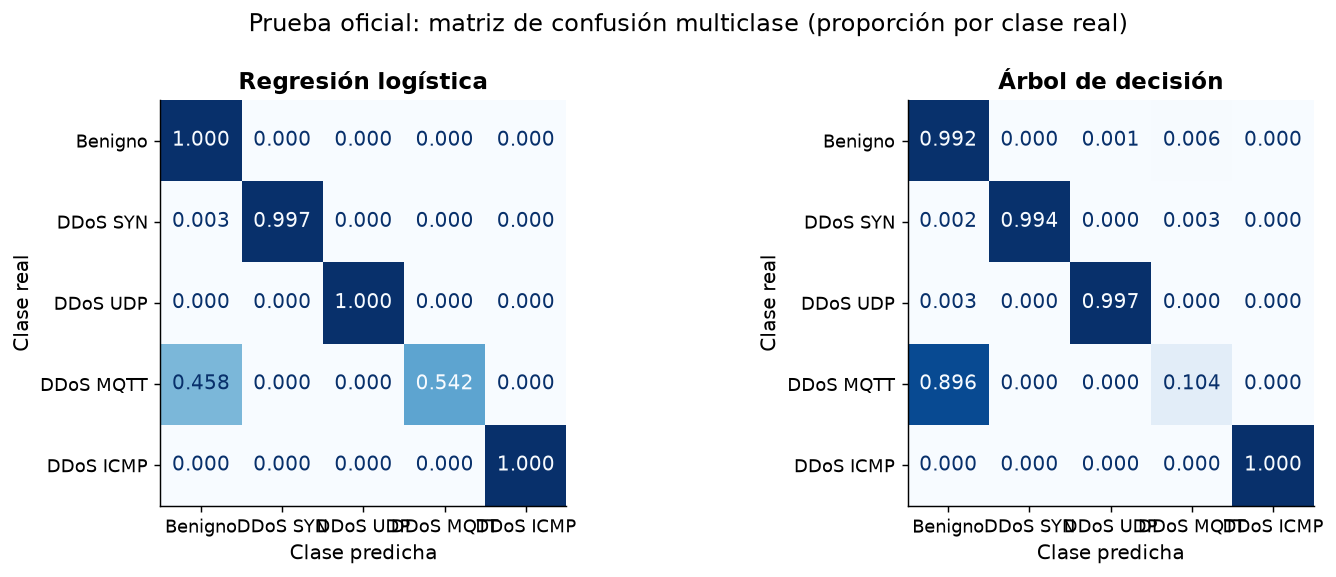

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, nombre in zip(axes, ["Regresión logística", "Árbol de decisión"]):
    matriz_confusion(
        test["clase"], multiclase[nombre].predict(test[variables]),
        "multiclase", nombre, ax=ax, normalizar="true",
    )
fig.suptitle("Prueba oficial: matriz de confusión multiclase (proporción por clase real)")
plt.tight_layout()
plt.show()

## 3. Variables utilizadas por el árbol multiclase

,Importancia
AVG,0.4944
ICMP,0.2520
fin_count,0.2454
syn_flag_number,0.0063
TCP,0.0011
UDP,0.0009
Duration,0.0000
Variance,0.0000
ack_count,0.0000
DHCP,0.0000


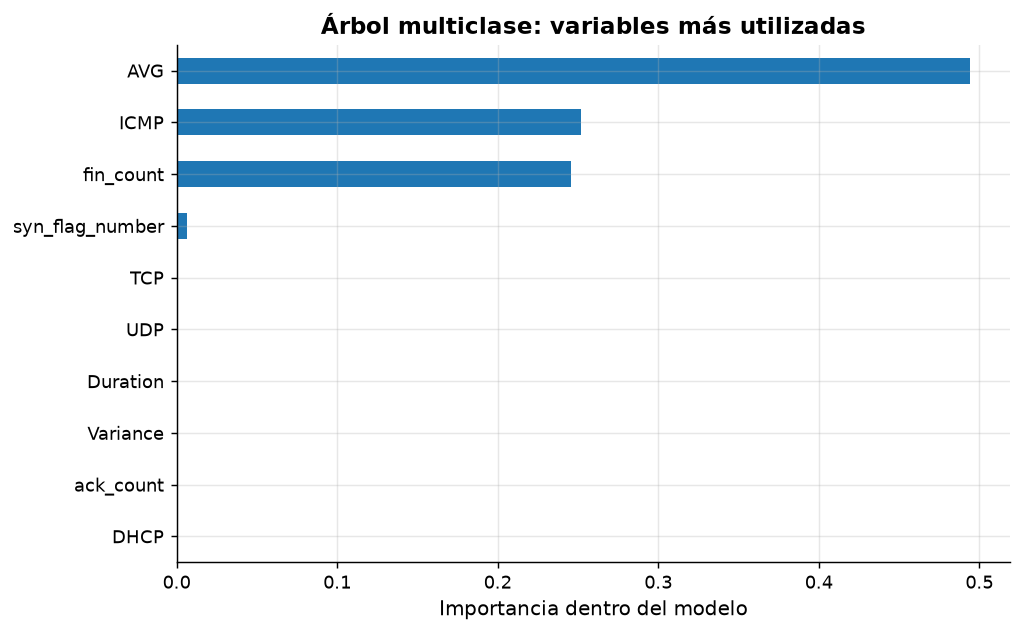

In [7]:
arbol = multiclase["Árbol de decisión"]
importancias = pd.Series(
    arbol[-1].feature_importances_, index=variables
).sort_values(ascending=False)

display(importancias.head(10).rename("Importancia").to_frame().round(4))

importancias.head(10).sort_values().plot.barh(
    figsize=(8, 5), title="Árbol multiclase: variables más utilizadas"
)
plt.xlabel("Importancia dentro del modelo")
plt.tight_layout()
plt.show()

In [8]:
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)
joblib.dump(binarios[(ESCENARIO_COMPLETO, "Árbol de decisión")],
            CARPETA_MODELOS / "arbol_binario.joblib")
joblib.dump(multiclase["Árbol de decisión"],
            CARPETA_MODELOS / "arbol_multiclase.joblib")
print("Modelos guardados en", CARPETA_MODELOS)

Modelos guardados en /Users/makise/Documents/GitHub/Data-Science/Sin título/models


## Conclusiones de la línea base

> Las cifras de estas conclusiones corresponden a la ejecución con tres clases (benigno, SYN y UDP), la que se presentó en la Presentación 2. Al ejecutar con cinco clases, comparar con las nuevas salidas y actualizarlas.

Resultados en la **prueba oficial** (captura separada, 415.658 flujos):

1. **Clase mayoritaria frente a modelos entrenados.** Decir siempre «DDoS»
   logra 90,95 % de accuracy en la prueba oficial, pero su F1 macro es 0,476
   (binaria) y 0,221 (multiclase), con 100 % de falsos positivos. La regresión
   logística y el árbol llegan a F1 macro ≈ 0,995 (binaria V2) y ≈ 0,996–0,997
   (multiclase), con una tasa de falsos positivos entre 0,02 % y 0,03 %. Por eso
   se reportan F1 macro, recall por clase y falsos positivos, no accuracy.
2. **V1 frente a V2.** Entrenado solo con benigno + SYN (V1), el árbol no detecta
   ningún UDP flood: recall UDP = 0 y 206.203 ataques UDP pasan como benignos
   (206.141 con regresión logística). Al incluir UDP en el entrenamiento (V2) el
   recall UDP sube a 0,999. Un detector es ciego a las variantes de DDoS que no
   vio.
3. **Validación frente a prueba oficial.** En multiclase el F1 macro baja de
   0,9997 a 0,9968 (regresión logística) y de 0,9996 a 0,9963 (árbol). La caída
   (~0,003) es pequeña y parecida en ambos modelos: viene del cambio entre
   capturas, no de un modelo en particular.
4. **Clases que se confunden.** Los errores son casi todos DDoS SYN predicho como
   benigno (recall SYN ≈ 0,997); UDP y benigno se separan casi sin error.

Esta es la referencia que deben superar los ensambles del notebook 04.
